# 2 · Resultados, explicação, equidade e predição

Este notebook **treina ao vivo** os quatro modelos no par 2022→2023 e testa no par 2023→2024, que eles nunca viram. É o teste do ano nunca visto, que reproduz o uso real. Depois mostra o laudo de uma escola, o viés medido e o ranking de 2025.

O XGBoost usa a configuração serializada em `models/xgboost_v1.joblib` (a do notebook 08), clonada e re-treinada só no ano de treino. Ridge e Random Forest usam os hiperparâmetros escolhidos no notebook 06. Nada é gravado em disco.

| Seção | Slide |
|---|---|
| 1. Teste do ano nunca visto (Quadro 10) | 14–15 |
| 2. Quanto a lista alcança | 16 |
| 3. Por que o sistema indica (SHAP) | 17 |
| 4. Laudo de uma escola | 18 |
| 5. Equidade | 19 |
| 6. Ranking de 2025 | 20 |

In [1]:
import logging, sys, time, warnings
from pathlib import Path

# Raiz do projeto (evasao-escolar/): sobe a partir da pasta do notebook até achar src/.
ROOT = Path.cwd()
while not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

logging.disable(logging.INFO)          # sem o log INFO do pipeline na tela
warnings.filterwarnings("ignore")
pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

CINZA, AZUL, VERDE, VERMELHO = "#9E9E9E", "#1565C0", "#2E7D32", "#C62828"
print("Projeto:", ROOT)

Projeto: F:\repos\evasao-escolar\evasao-escolar


## 1. Teste do ano nunca visto

Treina com as características de 2022 e o abandono de 2023, e prevê o abandono de 2024 a partir das características de 2023.

In [2]:
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import roc_auc_score

from src.models.evaluate import calcular_metricas
from src.models.train import (RANDOM_STATE, TARGET_COL, ANO_COL, carregar_dataset, carregar_modelo,
                              colunas_features, criar_pipeline, preparar_xy, split_temporal)

df = carregar_dataset()
treino, teste = split_temporal(df)
X_tr, y_tr, _ = preparar_xy(treino)
X_te, y_te, _ = preparar_xy(teste)
print(f"Treino: {len(X_tr)} escolas (2022→2023) | Teste: {len(X_te)} escolas (2023→2024)")

modelos = {
    "Sem sistema (média)": criar_pipeline(X_tr, DummyRegressor(strategy="mean")),
    "Ridge (linear)": criar_pipeline(X_tr, Ridge(alpha=100.0, random_state=RANDOM_STATE)),
    "Random Forest": criar_pipeline(X_tr, RandomForestRegressor(
        n_estimators=300, max_depth=8, min_samples_leaf=5, random_state=RANDOM_STATE, n_jobs=-1)),
    "XGBoost (adotado)": clone(carregar_modelo("xgboost_v1")),
}

previsto, linhas = {}, []
for nome, m in modelos.items():
    t0 = time.time()
    m.fit(X_tr, y_tr)
    previsto[nome] = np.asarray(m.predict(X_te), dtype=float)
    met = calcular_metricas(y_te, previsto[nome])
    linhas.append({"modelo": nome, "Spearman": met["spearman"], "Precision@K": met["precision_at_k"],
                   "RMSE": met["rmse"], "R²": met["r2"], "treino (s)": time.time() - t0})
quadro10 = pd.DataFrame(linhas).set_index("modelo")
print(f"K = {met['k']} escolas (10% do teste)")
display(quadro10.style.format("{:.3f}", na_rep="—"))

Treino: 797 escolas (2022→2023) | Teste: 789 escolas (2023→2024)


K = 79 escolas (10% do teste)


,Spearman,Precision@K,RMSE,R²,treino (s)
modelo,,,,,
Sem sistema (média),—,0.089,2.540,-0.038,0.016
Ridge (linear),0.330,0.380,2.891,-0.344,0.016
Random Forest,0.343,0.405,2.751,-0.217,0.390
XGBoost (adotado),0.348,0.418,2.874,-0.329,0.163


**Leitura.** No erro do valor (RMSE), nenhum modelo supera a média: o XGBoost tem R² negativo. No acerto da lista (Precision@K) o ganho é de cerca de 4,7× sobre o acaso. Os três modelos ficam próximos entre si: o XGBoost não é superior em tudo.

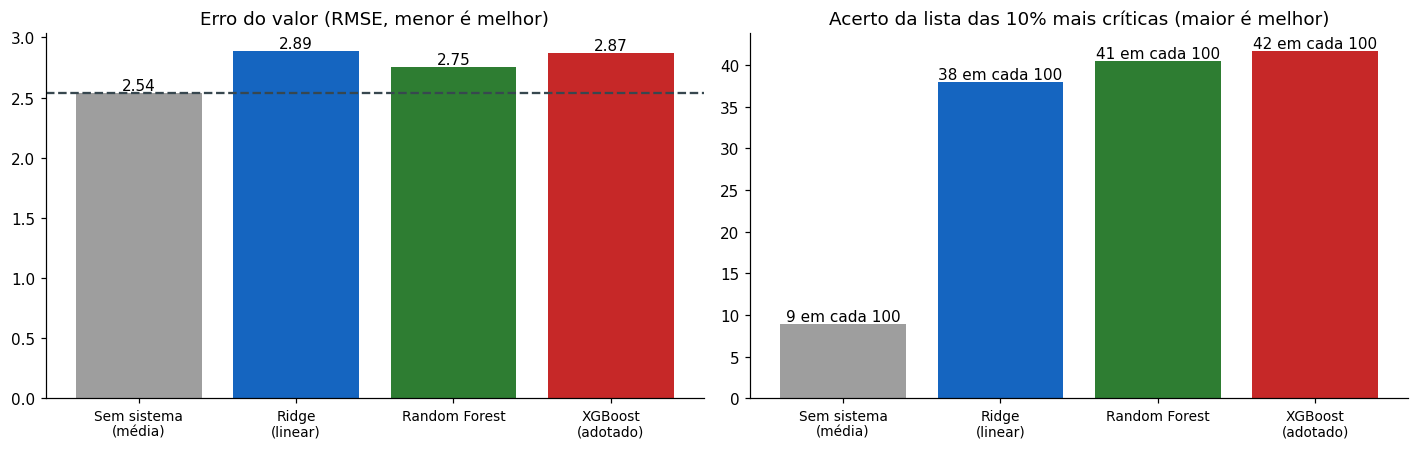

Ganho do XGBoost sobre o acaso na lista: 4.7×


In [3]:
cores = [CINZA, AZUL, VERDE, VERMELHO]
nomes = [n.replace(" (", "\n(") for n in quadro10.index]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.2))
b = a1.bar(nomes, quadro10["RMSE"], color=cores)
a1.axhline(quadro10["RMSE"].iloc[0], ls="--", color="#37474F")
a1.bar_label(b, fmt="%.2f"); a1.set_title("Erro do valor (RMSE, menor é melhor)")
b = a2.bar(nomes, quadro10["Precision@K"] * 100, color=cores)
a2.bar_label(b, labels=[f"{v * 100:.0f} em cada 100" for v in quadro10["Precision@K"]])
a2.set_title("Acerto da lista das 10% mais críticas (maior é melhor)")
for a in (a1, a2):
    a.tick_params(axis="x", labelsize=9)
plt.tight_layout(); plt.show()

ganho = quadro10.loc["XGBoost (adotado)", "Precision@K"] / quadro10.loc["Sem sistema (média)", "Precision@K"]
print(f"Ganho do XGBoost sobre o acaso na lista: {ganho:.1f}×")

## 2. Quanto a lista alcança

*Escola crítica* = está entre os 10% de maior abandono **real** em 2024. Duas perguntas diferentes:
- **Separação (ROC AUC):** para um par crítica × não crítica, com que frequência o sistema dá risco maior à crítica (0,5 = acaso).
- **Alcance:** se a Secretaria visitar as N primeiras da lista, quantas das críticas ela encontra.

Críticas: 80 escolas com abandono ≥ 2.7% em 2024

  ROC AUC Ridge (linear)       0.802
  ROC AUC Random Forest        0.829
  ROC AUC XGBoost (adotado)    0.798


,críticas encontradas,alcance,ao acaso,precisão da lista
lista,,,,
50,22,28%,6%,44%
100,37,46%,13%,37%
150,46,57%,19%,31%


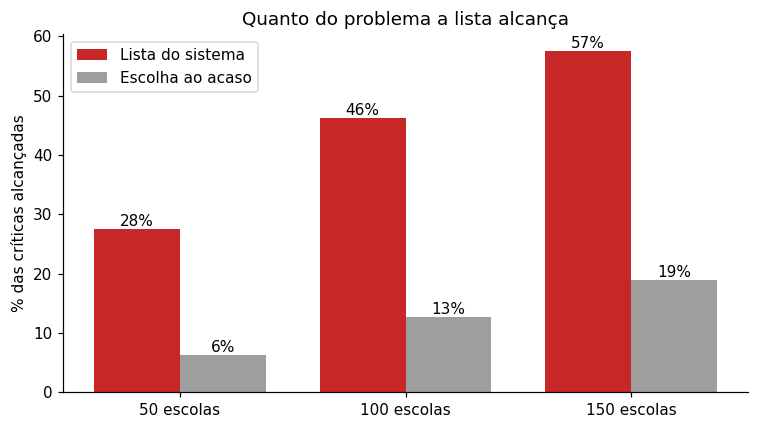

In [4]:
y_arr = y_te.to_numpy()
limiar = np.percentile(y_arr, 90)
critica = y_arr >= limiar
print(f"Críticas: {critica.sum()} escolas com abandono ≥ {limiar:.1f}% em 2024\n")

for nome in list(modelos)[1:]:
    print(f"  ROC AUC {nome:<20} {roc_auc_score(critica, previsto[nome]):.3f}")

p = previsto["XGBoost (adotado)"]
ordem = np.argsort(-p)
alc = []
for n in (50, 100, 150):
    acertos = critica[ordem[:n]].sum()
    alc.append({"lista": n, "críticas encontradas": acertos, "alcance": acertos / critica.sum(),
                "ao acaso": n / len(y_arr), "precisão da lista": acertos / n})
alc = pd.DataFrame(alc).set_index("lista")
display(alc.style.format({"alcance": "{:.0%}", "ao acaso": "{:.0%}", "precisão da lista": "{:.0%}"}))

fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(alc)); w = 0.38
b1 = ax.bar(x - w / 2, alc["alcance"] * 100, w, color=VERMELHO, label="Lista do sistema")
b2 = ax.bar(x + w / 2, alc["ao acaso"] * 100, w, color=CINZA, label="Escolha ao acaso")
ax.bar_label(b1, fmt="%.0f%%"); ax.bar_label(b2, fmt="%.0f%%")
ax.set_xticks(x, [f"{n} escolas" for n in alc.index]); ax.set_ylabel("% das críticas alcançadas")
ax.set_title("Quanto do problema a lista alcança"); ax.legend()
plt.tight_layout(); plt.show()

## 3. Por que o sistema indica: SHAP

O modelo final (treinado em 2022 e 2023) decompõe cada previsão em quanto cada característica contribuiu. A tabela é a média do peso absoluto em todas as observações, a mesma que gera `reports/shap_importancia.csv`. **A leitura é diagnóstica, não causal.**

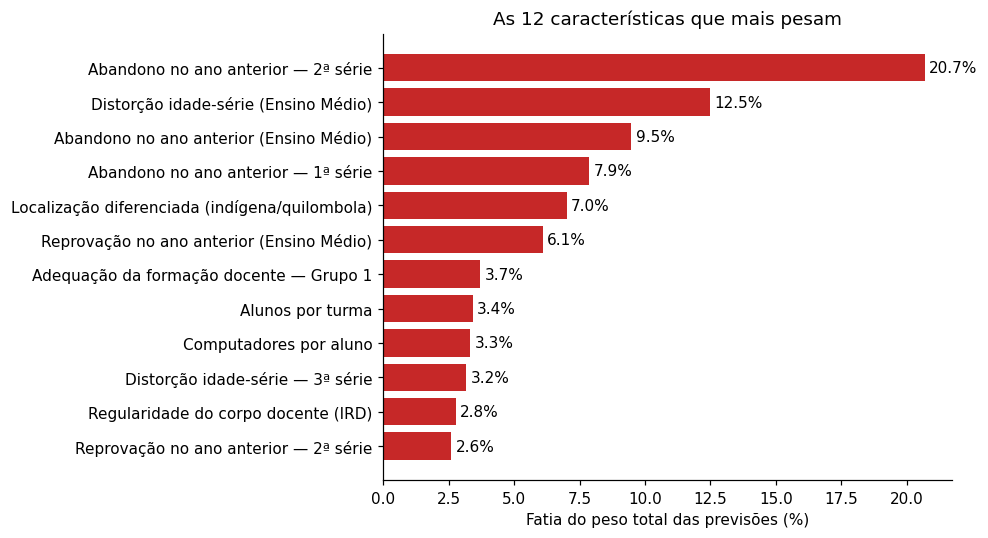

,feature,característica,shap_mean_abs
0,abnd_s2_t,Abandono no ano anterior — 2ª série,0.333
1,tdi_med_t,Distorção idade-série (Ensino Médio),0.201
2,abnd_t,Abandono no ano anterior (Ensino Médio),0.153
3,abnd_s1_t,Abandono no ano anterior — 1ª série,0.127
4,is_loc_diferenciada,Localização diferenciada (indígena/quilombola),0.113
5,reprov_t,Reprovação no ano anterior (Ensino Médio),0.098


In [5]:
from src.models.explain import calcular_shap_values, importancia_shap, direcao_features
from src.recommend.labels import rotular_feature

modelo_final = carregar_modelo("xgboost_v1")
sv = calcular_shap_values(modelo_final, df[colunas_features(df)])
imp = importancia_shap(sv)
imp["fatia"] = imp["shap_mean_abs"] / imp["shap_mean_abs"].sum()
imp["característica"] = imp["feature"].map(rotular_feature)

top = imp.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5))
b = ax.barh(top["característica"], top["fatia"] * 100, color=VERMELHO)
ax.bar_label(b, labels=[f"{v * 100:.1f}%" for v in top["fatia"]], padding=3)
ax.set_xlabel("Fatia do peso total das previsões (%)")
ax.set_title("As 12 características que mais pesam")
plt.tight_layout(); plt.show()
display(imp.head(6)[["feature", "característica", "shap_mean_abs"]])

## 4. Laudo de uma escola

É o que o gestor vê na aba *Detalhe da escola* do painel. `ServicoPriorizacao` é a camada de serviço que o Streamlit consome: a regra de negócio vive aqui, testável sem a interface. Abaixo, a escola de maior risco previsto na base histórica.

In [6]:
from src.recommend.service import ServicoPriorizacao, ressalva_equidade

servico = ServicoPriorizacao.criar()
rk = servico.ranking(ano=2022, top_k=10)
display(rk.head(5)[["NO_ENTIDADE", "NO_MUNICIPIO", "localizacao", "risco_previsto", "abandono_real", "diagnostico"]])

escola = rk.iloc[0]
info, contribs = servico.explicar_escola(int(escola.CO_ENTIDADE), 2022, top_n=8)
print(f"\n{info.NO_ENTIDADE} ({info.NO_MUNICIPIO}) — características de 2022")
print(f"Risco previsto para 2023: {info.risco_previsto:.1f}% | observado: {info.abandono_real:.1f}%\n")
for c in contribs:
    valor = "" if c.valor is None else f"(valor: {c.valor:.2f})"
    print(f"  {c.direcao:<16} {c.rotulo:<55} {valor}")

aviso = ressalva_equidade(info.localizacao)
if aviso:
    print("\n⚠ RESSALVA DE EQUIDADE:", aviso)

,NO_ENTIDADE,NO_MUNICIPIO,localizacao,risco_previsto,abandono_real,diagnostico
0,ESCOLA ESTADUAL INDIGENA JOSE LUCIANO,Jatobá,Diferenciada (indígena/quilombola),28.708,39.1,Alerta (abandona mais que o previsto)
1,ESCOLA DO ESPINHEIRO,Tacaratu,Diferenciada (indígena/quilombola),26.997,39.5,Alerta (abandona mais que o previsto)
2,ESCOLA ESTADUAL ORORUBA,Pesqueira,Diferenciada (indígena/quilombola),23.154,27.3,Alerta (abandona mais que o previsto)
3,ESCOLA ESTADUAL INDIGENA SANTA CLARA,Tacaratu,Diferenciada (indígena/quilombola),21.644,23.7,Alerta (abandona mais que o previsto)
4,ESCOLA ESTADUAL JOSE FERREIRA DA SILVA,Floresta,Diferenciada (indígena/quilombola),21.533,32.5,Alerta (abandona mais que o previsto)



ESCOLA ESTADUAL INDIGENA JOSE LUCIANO (Jatobá) — características de 2022
Risco previsto para 2023: 28.7% | observado: 39.1%

  ↑ aumenta risco  Distorção idade-série (Ensino Médio)                    (valor: 80.30)
  ↑ aumenta risco  Distorção idade-série — 3ª série                        (valor: 92.90)
  ↑ aumenta risco  Abandono no ano anterior (Ensino Médio)                 (valor: 29.30)
  ↑ aumenta risco  Abandono no ano anterior — 2ª série                     (valor: 13.00)
  ↑ aumenta risco  Distorção idade-série — 2ª série                        (valor: 69.60)
  ↑ aumenta risco  Reprovação no ano anterior (Ensino Médio)               (valor: 14.70)
  ↑ aumenta risco  Alunos por turma                                        (valor: 15.20)
  ↑ aumenta risco  Localização diferenciada (indígena/quilombola)          (valor: 1.00)

⚠ RESSALVA DE EQUIDADE: Escola de localização diferenciada (indígena/quilombola). Neste grupo o modelo **superestima** o risco: no diagnóstico temporal, a

## 5. Equidade: o limite que precisa ser declarado

Resíduo = abandono real − previsto, no teste do ano nunca visto. Negativo quer dizer que o sistema previu **mais** do que aconteceu.

,escolas,previsto,real,erro_medio
grupo,,,,
urbana,679,0.556,0.630,0.074
rural,69,0.498,0.878,0.380
diferenciada,41,11.076,4.961,-6.115


Diferenciadas superestimadas: 80% das 41
Diferenciadas na lista das 79 de maior risco: 39


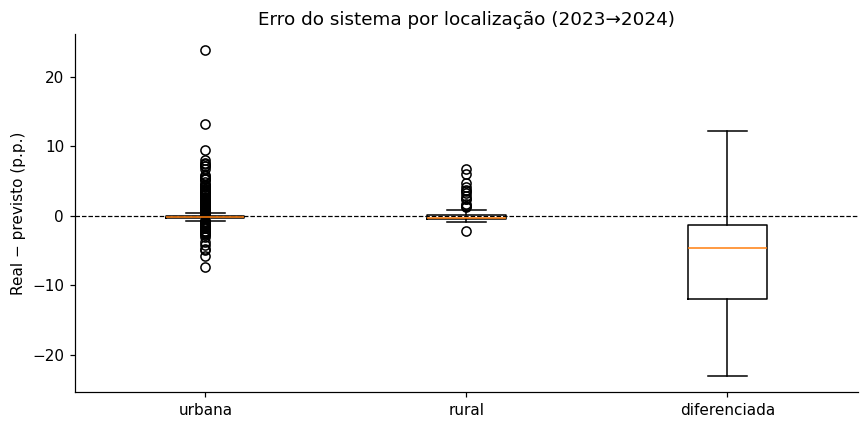

In [7]:
from src.models.explain import residuos_validacao_temporal, resumo_residuos_por_grupo

res = residuos_validacao_temporal(carregar_modelo("xgboost_v1"), df)
resumo = res.groupby("grupo").agg(escolas=("residuo", "size"), previsto=("y_pred", "mean"),
                                  real=("y_real", "mean"), erro_medio=("residuo", "mean"))
display(resumo.reindex(["urbana", "rural", "diferenciada"]))

dif = res[res.grupo == "diferenciada"]
top79 = res.nlargest(79, "y_pred")
print(f"Diferenciadas superestimadas: {(dif.residuo < 0).mean():.0%} das {len(dif)}")
print(f"Diferenciadas na lista das 79 de maior risco: {(top79.grupo == 'diferenciada').sum()}")

fig, ax = plt.subplots(figsize=(8, 4))
grupos = ["urbana", "rural", "diferenciada"]
ax.boxplot([res.loc[res.grupo == g, "residuo"] for g in grupos], tick_labels=grupos, showfliers=True)
ax.axhline(0, ls="--", color="black", lw=0.8)
ax.set_ylabel("Real − previsto (p.p.)"); ax.set_title("Erro do sistema por localização (2023→2024)")
plt.tight_layout(); plt.show()

## 6. Ranking de 2025

Modo predição: as características de 2024 entram no modelo final e saem as escolas ordenadas pelo risco de 2025 (`python -m src.models.predict 2024`). A coluna de ressalva acompanha a lista, porque a planilha circula fora do painel.

In [8]:
from src.features.build_features import construir_dataset_predicao
from src.models.predict import prever_ano
from src.recommend.service import ressalva_equidade_curta, LOC_DIFERENCIADA

ranking = prever_ano(2024)
loc24 = construir_dataset_predicao(2024)[["CO_ENTIDADE", "is_loc_diferenciada"]]
ranking = ranking.merge(loc24, on="CO_ENTIDADE", how="left")
ranking["ressalva"] = [ressalva_equidade_curta(LOC_DIFERENCIADA) if v == 1 else ""
                       for v in ranking.is_loc_diferenciada]

print(f"{len(ranking)} escolas ordenadas pelo risco de abandono em 2025\n")
display(ranking.head(10)[["posicao", "NO_ENTIDADE", "NO_MUNICIPIO", "risco_abandono_previsto", "ressalva"]]
        .style.format({"risco_abandono_previsto": "{:.1f}%"}).hide(axis="index"))

791 escolas ordenadas pelo risco de abandono em 2025



posicao,NO_ENTIDADE,NO_MUNICIPIO,risco_abandono_previsto,ressalva
1,ESCOLA ESTADUAL INDIGENA ACELINA COSME DE MOURA,Floresta,17.7%,"Risco superestimado em ~6 p.p. neste grupo (indígena/quilombola) — usar como sinal de atenção, não como magnitude"
2,ESCOLA ESTADUAL INDIGENA QUITERIA MARIA DE JESUS,Jatobá,13.6%,"Risco superestimado em ~6 p.p. neste grupo (indígena/quilombola) — usar como sinal de atenção, não como magnitude"
3,ESCOLA ESTADUAL INDIGENA SANTA CLARA,Tacaratu,13.2%,"Risco superestimado em ~6 p.p. neste grupo (indígena/quilombola) — usar como sinal de atenção, não como magnitude"
4,ESCOLA ESTADUAL ORORUBA,Pesqueira,11.6%,"Risco superestimado em ~6 p.p. neste grupo (indígena/quilombola) — usar como sinal de atenção, não como magnitude"
5,ESCOLA ESTADUAL INDIGENA LUIZ PEREIRA LEAL,Itacuruba,11.5%,"Risco superestimado em ~6 p.p. neste grupo (indígena/quilombola) — usar como sinal de atenção, não como magnitude"
6,ESCOLA MENINO JESUS,Floresta,11.4%,"Risco superestimado em ~6 p.p. neste grupo (indígena/quilombola) — usar como sinal de atenção, não como magnitude"
7,ESCOLA ESTADUAL INDIGENA JOSEFA ALICE DA CONCEICAO,Itacuruba,9.7%,"Risco superestimado em ~6 p.p. neste grupo (indígena/quilombola) — usar como sinal de atenção, não como magnitude"
8,ESCOLA PRINCESA ISABEL,Tacaratu,9.7%,"Risco superestimado em ~6 p.p. neste grupo (indígena/quilombola) — usar como sinal de atenção, não como magnitude"
9,ESCOLA TIBURCIO LIMA,Floresta,9.6%,"Risco superestimado em ~6 p.p. neste grupo (indígena/quilombola) — usar como sinal de atenção, não como magnitude"
10,ESCOLA DO ESPINHEIRO,Tacaratu,9.1%,"Risco superestimado em ~6 p.p. neste grupo (indígena/quilombola) — usar como sinal de atenção, não como magnitude"


## O que este notebook mostrou

- O sistema **acerta a ordem, não o valor**: erra a taxa mais que a média, mas a lista acerta cerca de 4,7× mais que o acaso.
- Os três modelos ficam próximos. O XGBoost foi adotado pelo teste do ano nunca visto e pela explicação construída sobre ele, não por superioridade geral.
- Cada indicação vem com o porquê. A leitura é diagnóstica, não causal.
- Há um **viés medido** nas escolas de localização diferenciada, declarado no painel e na planilha.